# Precipitation and CWV Cross-Spectral Analysis

Use the precipitation and column-water-vapor files from `Qr_Prec.ipynb` and
`Qr_CWV.ipynb`, respectively, with the shared `src/cross_spectrum_ana.py` workflow.
Precipitation is the source and CWV is the reference. The analysis uses daily data
from 2006–2017, 5°S–5°N, symmetric meridional components, and 96-day segments
with 48-day overlap. Each segment is linearly detrended and Hann tapered.

The figure shows normalized co-spectrum as shading and squared coherence as
contours, with the same dispersion curves and wave-domain summaries as the
reference notebooks. Input files retain their existing preprocessing; no
additional seasonal-harmonic removal is applied here.

## 1. Imports and configuration

In [1]:
import sys
from pathlib import Path

import netCDF4 as nc
import numpy as np
from matplotlib import pyplot as plt
from scipy.interpolate import interp1d

PROJECT_PATH = Path("/home/b11209013/Manuscript_Prep/KW_CRI")
if str(PROJECT_PATH / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_PATH / "src"))
import cross_spectrum_ana as workflow

DATA_PATH = Path("/data92/b11209013")
PRECIPITATION_FILE = DATA_PATH / "IMERG" / "DATA" / "IMERG_1deg.nc"
CWV_FILE = DATA_PATH / "ERA5_GRIB" / "Data" / "regrid" / "CWV.nc"
OUTPUT_PATH = PROJECT_PATH / "Figure" / "Prec_CWV"
START_DATE = "2006-01-01"
END_DATE = "2018-01-01"  # Exclusive.
LATITUDE_BOUNDS = (-5.0, 5.0)
WINDOW_SIZE = 96
OVERLAP_SIZE = WINDOW_SIZE // 2
SAMPLING_INTERVAL_DAYS = 1.0
MERIDIONAL_COMPONENT = "symmetric"
SOURCE_NAME = "Precipitation"
REFERENCE_KEY = "CWV"
COHERENCE_LEVELS = (0.3, 0.4, 0.5, 0.6, 0.8)
EQUIVALENT_DEPTHS = (8.0, 90.0)

## 2. Decode dates and load the requested period

IMERG uses CF time units (`days since ...`); CWV uses `day as %Y%m%d.%f`.
Match these daily products by calendar date, ignoring the fractional-day label
in CWV. Reject duplicate dates, gaps, or incomplete coverage of the requested
period rather than treating separated days as consecutive FFT samples.

In [2]:
def as_float_array(values):
    """Convert NetCDF values to float32 and replace masks with NaN."""
    return np.asarray(np.ma.asarray(values, dtype=np.float32).filled(np.nan))


def convert_daily_dates(time_variable):
    """Decode CF or YYYYMMDD.fraction time coordinates to calendar days."""
    units = time_variable.units
    if units.strip() == "day as %Y%m%d.%f":
        values = np.ma.asarray(time_variable[:])
        if np.any(np.ma.getmaskarray(values)) or not np.all(np.isfinite(values)):
            raise ValueError("The time coordinate contains missing values.")
        date_strings = [f"{int(value):08d}" for value in values]
        return np.asarray(
            [f"{date[:4]}-{date[4:6]}-{date[6:8]}" for date in date_strings],
            dtype="datetime64[D]",
        )
    dates = nc.num2date(
        time_variable[:], units=units,
        calendar=getattr(time_variable, "calendar", "standard"),
    )
    return np.asarray([date.strftime("%Y-%m-%d") for date in dates], dtype="datetime64[D]")


def load_daily_field(path, variable_name, latitude_margin=0.0):
    """Load only the requested dates and latitude band, in time/lat/lon order."""
    with nc.Dataset(path) as dataset:
        dates = convert_daily_dates(dataset.variables["time"])
        latitude = as_float_array(dataset.variables["lat"][:])
        longitude = as_float_array(dataset.variables["lon"][:])
        date_mask = (dates >= np.datetime64(START_DATE)) & (dates < np.datetime64(END_DATE))
        latitude_mask = (
            (latitude >= LATITUDE_BOUNDS[0] - latitude_margin)
            & (latitude <= LATITUDE_BOUNDS[1] + latitude_margin)
        )
        if not np.any(date_mask) or not np.any(latitude_mask):
            raise ValueError(f"No data selected from {path}.")
        variable = dataset.variables[variable_name]
        if variable.dimensions != ("time", "lat", "lon"):
            raise ValueError(f"Unexpected dimensions for {variable_name}: {variable.dimensions}")
        field = as_float_array(variable[date_mask, latitude_mask, :])
    return dates[date_mask], latitude[latitude_mask], longitude, field


# Include neighboring precipitation latitudes so interpolation never extrapolates.
precipitation_dates, precipitation_latitude, precipitation_longitude, precipitation = (
    load_daily_field(PRECIPITATION_FILE, "precipitation", latitude_margin=1.0)
)
cwv_dates, cwv_latitude, cwv_longitude, cwv = load_daily_field(CWV_FILE, "CWV")

## 3. Align dates and spatial coordinates

The supplied precipitation latitude centers are offset by 0.1° from CWV, and
CWV latitude is descending. Sort both fields south-to-north, then linearly
interpolate precipitation in latitude onto the CWV centers (−4.5° to 4.5°).
Longitudes must match on a uniformly spaced global grid. Symmetric and
antisymmetric decomposition require latitude pairs centered on the equator.

In [3]:
expected_dates = np.arange(
    np.datetime64(START_DATE, "D"), np.datetime64(END_DATE, "D"),
    np.timedelta64(1, "D"),
)
if SAMPLING_INTERVAL_DAYS != 1.0:
    raise ValueError("These inputs are daily products; use SAMPLING_INTERVAL_DAYS = 1.0.")
for name, dates in ((SOURCE_NAME, precipitation_dates), (REFERENCE_KEY, cwv_dates)):
    if not np.array_equal(dates, expected_dates):
        raise ValueError(f"{name} must have exactly one ordered sample per requested day.")

precipitation_order = np.argsort(precipitation_latitude)
cwv_order = np.argsort(cwv_latitude)
precipitation_latitude = precipitation_latitude[precipitation_order]
precipitation = precipitation[:, precipitation_order, :]
latitude = cwv_latitude[cwv_order]
cwv = cwv[:, cwv_order, :]
if np.any(np.diff(precipitation_latitude) <= 0) or np.any(np.diff(latitude) <= 0):
    raise ValueError("Latitude coordinates must be unique.")
if MERIDIONAL_COMPONENT != "none" and not np.allclose(latitude, -latitude[::-1], atol=1e-5):
    raise ValueError("The target latitudes must pair symmetrically about the equator.")
if precipitation_longitude.shape != cwv_longitude.shape or not np.allclose(
    precipitation_longitude, cwv_longitude, rtol=0, atol=1e-5
):
    raise ValueError("Precipitation and CWV longitude coordinates do not match.")
longitude = cwv_longitude
if longitude.size < 2 or not np.allclose(
    np.diff(longitude), 360.0 / longitude.size, rtol=0, atol=1e-5
):
    raise ValueError("The FFT requires an increasing, uniformly spaced global longitude grid.")

precipitation = interp1d(
    precipitation_latitude, precipitation, axis=1,
    kind="linear", bounds_error=True, assume_sorted=True,
)(latitude).astype(np.float32)
source_fields = {SOURCE_NAME: precipitation}
reference_field = cwv
workflow.validate_aligned_fields(source_fields, reference_field)
print(f"Aligned dates: {expected_dates[0]} to {expected_dates[-1]} ({expected_dates.size} days)")
print(f"Aligned shape (time, latitude, longitude): {reference_field.shape}")
print(f"Latitude centers: {latitude[0]:.1f} to {latitude[-1]:.1f} degrees")

Aligned dates: 2006-01-01 to 2017-12-31 (4383 days)
Aligned shape (time, latitude, longitude): (4383, 10, 360)
Latitude centers: -4.5 to 4.5 degrees


## 4. Remove time-zonal means and select the meridional component

In [4]:
source_anomalies = {
    name: workflow.remove_time_zonal_mean(field)
    for name, field in source_fields.items()
}
reference_anomaly = workflow.remove_time_zonal_mean(reference_field)
source_components = {
    name: workflow.select_meridional_component(field, MERIDIONAL_COMPONENT)
    for name, field in source_anomalies.items()
}
reference_component = workflow.select_meridional_component(
    reference_anomaly, MERIDIONAL_COMPONENT
)
workflow.validate_aligned_fields(source_components, reference_component)

## 5. Detrend and Hann taper overlapping segments

In [5]:
chunked_fields = workflow.segment_fields(
    {**source_components, REFERENCE_KEY: reference_component},
    window_size=WINDOW_SIZE,
    overlap_size=OVERLAP_SIZE,
)
source_chunks = {name: chunked_fields[name] for name in source_components}
reference_chunks = chunked_fields[REFERENCE_KEY]
n_segments, _, n_latitudes, n_longitudes = reference_chunks.shape
print(f"Windowed shape (segment, time, latitude, longitude): {reference_chunks.shape}")

Windowed shape (segment, time, latitude, longitude): (90, 96, 10, 360)


## 6. Calculate and average spectra

The shared workflow computes the time–longitude transform for each latitude,
forms cross- and auto-spectra, corrects for Hann-window energy, then averages
spectra over latitude and segments before calculating normalized diagnostics.

In [6]:
cross_spectrum, source_power_spectrum, reference_power_spectrum = (
    workflow.calculate_segment_spectra(
        source_chunks, reference_chunks, window_size=WINDOW_SIZE
    )
)
mean_cross_spectrum, mean_source_power_spectrum, mean_reference_power_spectrum = (
    workflow.average_segment_spectra(
        cross_spectrum, source_power_spectrum, reference_power_spectrum
    )
)

## 7. Normalized co-spectrum and squared coherence

For precipitation $P$ and CWV $W$, let $S_{PW}=F_P F_W^*$ and let angle brackets
denote the spectral averages above. The diagnostics are

$$C_N = \frac{\mathrm{Re}\langle S_{PW}\rangle}
{\sqrt{\langle S_{PP}\rangle\langle S_{WW}\rangle}}, \qquad
\gamma^2 = \frac{|\langle S_{PW}\rangle|^2}
{\langle S_{PP}\rangle\langle S_{WW}\rangle}.$$

Normalized co-spectrum ranges from −1 to 1; squared coherence ranges from 0 to 1.
Contour levels are descriptive values, not significance thresholds.

In [7]:
diagnostics = workflow.calculate_spectral_diagnostics(
    mean_cross_spectrum, mean_source_power_spectrum, mean_reference_power_spectrum
)
normalized_cospectrum = diagnostics["normalized_cospectrum"]
coherence_squared = diagnostics["coherence_squared"]
phase_degrees = diagnostics["phase_degrees"]
frequencies, zonal_wavenumbers = workflow.spectral_coordinates(
    window_size=WINDOW_SIZE,
    n_longitudes=n_longitudes,
    sampling_interval=SAMPLING_INTERVAL_DAYS,
)

## 8. Mean squared coherence within wave domains

Use the same Kelvin, Rossby, and MJO domains as the reference notebooks.
These are unweighted means of finite spectral bins. The bin counts do not
represent independent samples. With 96-day windows, the MJO domain includes
only the 48- and 32-day frequency bins at zonal wavenumbers 1–3.

In [8]:
wave_domain_coherence = workflow.average_wave_domain_coherence(
    zonal_wavenumbers,
    frequencies,
    coherence_squared[SOURCE_NAME],
    equivalent_depths=EQUIVALENT_DEPTHS,
)
print(f"{'Domain':<10} {'Mean coherence²':>17} {'Finite bins':>12}")
for domain, stats in wave_domain_coherence.items():
    print(f"{domain:<10} {stats['mean_coherence_squared']:>17.4f} {stats['n_bins']:>12d}")

Domain       Mean coherence²  Finite bins
Kelvin                0.3214           96
Rossby                0.3116           33
MJO                   0.6640            6


## 9. Plot and save the normalized co-spectrum with squared-coherence contours

Saved figure: /home/b11209013/Manuscript_Prep/KW_CRI/Figure/Prec_CWV/Prec_CWV.png


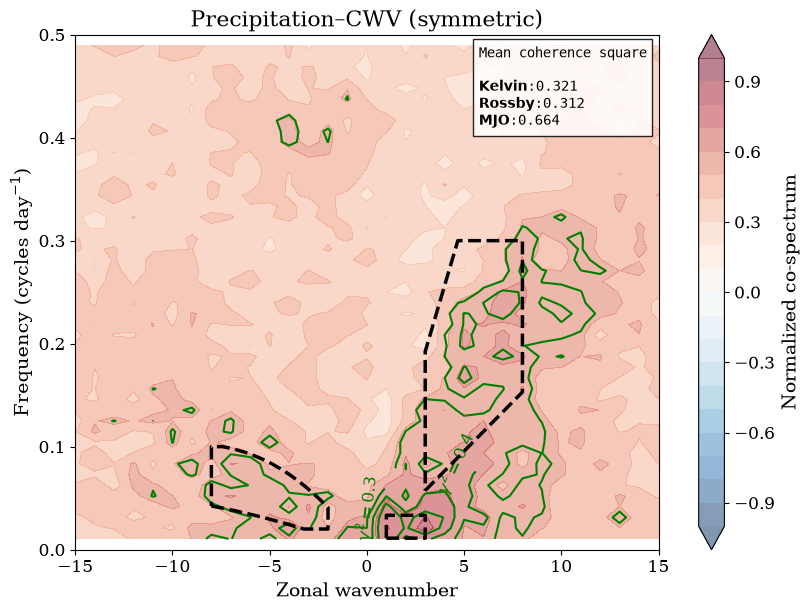

In [9]:
plot_data = workflow.prepare_plot_data(
    frequencies,
    zonal_wavenumbers,
    normalized_cospectrum[SOURCE_NAME],
    coherence_squared[SOURCE_NAME],
)
plt.rcParams.update({
    "font.family": "serif", "font.size": 14,
    "axes.labelsize": 14, "axes.titlesize": 16,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12,
})
figure, axis = workflow.plot_cospectrum_with_coherence(
    *plot_data,
    source_name=SOURCE_NAME,
    reference_name=REFERENCE_KEY,
    shading_levels=np.linspace(-1.0, 1.0, 21),
    coherence_levels=COHERENCE_LEVELS,
    equivalent_depths=EQUIVALENT_DEPTHS,
    cmap="RdBu_r",
    extend="both",
    colorbar_label="Normalized co-spectrum",
    x_limits=(-15.0, 15.0),
    y_limits=(0.0, 0.5),
)
axis.set_title(f"{SOURCE_NAME}–{REFERENCE_KEY} ({MERIDIONAL_COMPONENT})")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
figure_path = OUTPUT_PATH / "Prec_CWV.png"
figure.savefig(figure_path, dpi=600, bbox_inches="tight")
print(f"Saved figure: {figure_path}")
plt.show()